In [11]:
# read the fits file and print the header
from astropy.io import fits
hdul = fits.open('PJ46.fits')
print(hdul.info())
print(hdul[0].header)

Filename: PJ46.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       8   (3600, 1800)   float64   
  1                1 ImageHDU         9   (3600, 1800)   float64   
None
SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                  -64 / array data type                                NAXIS   =                    2 / number of array dimensions                     NAXIS1  =                 3600                                                  NAXIS2  =                 1800                                                  EXTEND  =                    T                                                  EXT_0   = 'M projection'                                                        EXT_1   = 'nbr_obs/pixel'                                                       END                                                                                                                                      

In [12]:
# read the data and print the shape
# read the fits file and print the header
from astropy.io import fits
hdul = fits.open('PJ46.fits')
data = hdul[0].data
print(data.shape)

(1800, 3600)


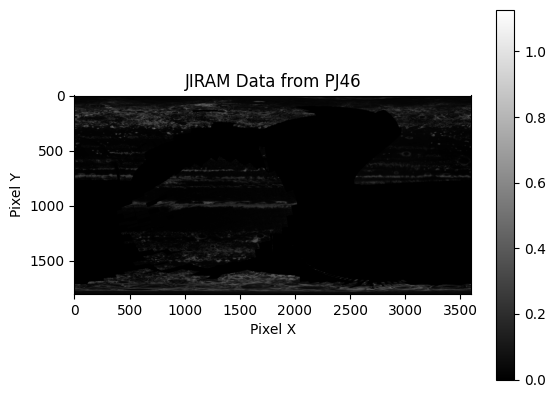

In [13]:
# plot the data
import matplotlib.pyplot as plt
plt.imshow(data, cmap='gray')
plt.colorbar()
plt.title('JIRAM Data from PJ46')
plt.xlabel('Pixel X')
plt.ylabel('Pixel Y')
plt.show()

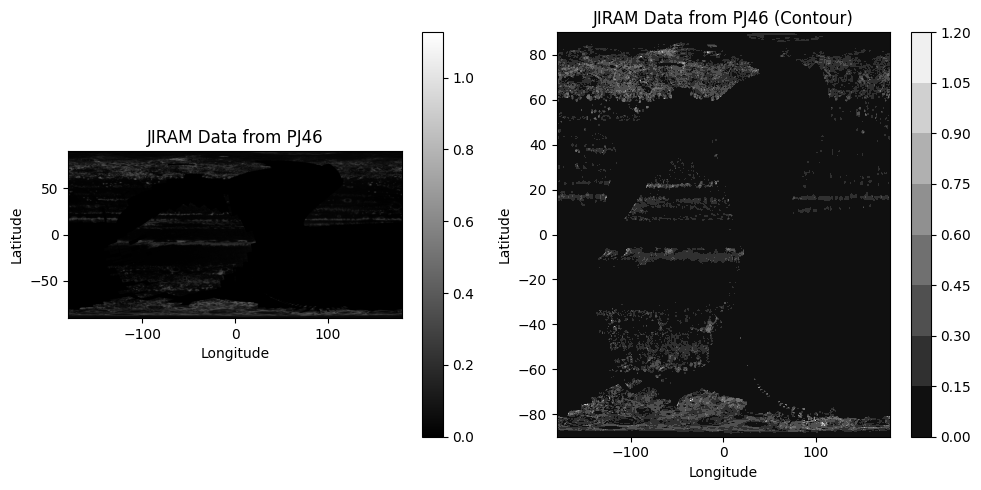

In [14]:
# generate the long and lat grid    
import numpy as np
lon = np.linspace(-180, 180, data.shape[1])
lat = np.linspace(90, -90, data.shape[0])
lon_grid, lat_grid = np.meshgrid(lon, lat)

# plot the data with long and lat grid
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(data, cmap='gray', extent=[-180, 180, -90, 90])
plt.colorbar()
plt.title('JIRAM Data from PJ46')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.subplot(1, 2, 2)
plt.contourf(lon, lat, data, cmap='gray')
plt.colorbar()
plt.title('JIRAM Data from PJ46 (Contour)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.tight_layout()
plt.show()




In [ ]:
# plot the north pole region, using ccrs.north_polar_stereographic
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import numpy as np
from matplotlib.colors import LogNorm

from astropy.io import fits

# lon = np.linspace(-180, 180, data.shape[1])
# lat = np.linspace(-90, 90, data.shape[0])
# # lon_grid, lat_grid = np.meshgrid(lon, lat)

for pj in [46, 47, 48]:
    hdul = fits.open(f'PJ{pj}.fits')
    data = hdul[0].data

    # inverse the first dimension of the data
    intens = data[::-1, :]

    intens = np.clip(intens, 0.01, 0.6)

    plt.figure(figsize=(8, 8), dpi=300)
    ax = plt.axes(projection=ccrs.NorthPolarStereo(central_longitude=-90))

    ax.set_extent([-180, 180, 75, 90], ccrs.PlateCarree())
    # plot data using a logarithmic color scale
    # cn=ax.contourf(lon, lat, data,cmap='inferno', transform=ccrs.PlateCarree(), norm=LogNorm(vmin=0.01, vmax=0.6))

    ax.set_xlim(-1.685e6, 1.685e6)
    ax.set_ylim(-1.685e6, 1.685e6)
    cn=ax.imshow(intens, cmap='inferno', transform=ccrs.PlateCarree(), norm=LogNorm(vmin=0.01, vmax=0.6))

    # plt.colorbar(cn, ax=ax, shrink=0.6, orientation='vertical')
    # ax.coastlines()
    # gl=ax.gridlines(draw_labels=True)
    # set x and y gridlines to be white and dashed

    ax.set_aspect("equal")

    for spine in ax.spines.values():
        spine.set_visible(False)

    for lon in range(0, -359, -30):
        if lon % 90 == 0:

            ha="center"
            if lon == 0 :
                ha="right"
            if lon == -180 :
                ha="left"

            # ax.text( lon, 75.3, f"{abs(lon)}°W",  color="white", transform=ccrs.PlateCarree(), rotation=0, ha=ha, va='center', zorder=5)


        ax.plot([lon]*100, np.linspace(70,90, 100), linestyle='--', color='w', alpha=1, lw=0.5, transform=ccrs.Geodetic(), zorder=3)

    for lat in range(70, 91, 5):
        # ax.text(-90-35, lat+0.5, f"{abs(lat)}°N", alpha=1, color="white", transform=ccrs.PlateCarree(),ha='right', va='center',zorder=5)
        ax.plot( np.linspace(-180,180, 600),[lat]*600, linestyle='--', color='w', alpha=1, lw=0.5, transform=ccrs.Geodetic(), zorder=3)

        # ax.text(-0.08, 1.02, f'{chr(i+97)}', transform=ax.transAxes, fontsize=18, fontweight='bold', va='top', ha='left')

    # plt.title('JIRAM Data from PJ46 (North Pole)')
    plt.show()